# Étape 4 — Analyse semi supervisée

**Objectif** : mesurer si les 1 311 images sans label, étiquetées par clustering à l'étape 3 (labels « faibles »), améliorent la détection des tumeurs par rapport aux seules 69 images labellisées par des radiologues (labels « forts »).

**Le modèle** : le ResNet-50 pré-entraîné de l'étape 2, gelé, surmonté d'une nouvelle tête de classification `Linear(2048, 2)`. Seule la tête est entraînée, directement sur les embeddings déjà calculés.

**Trois approches**, évaluées sur le même jeu de test de 30 images (15 cancers), jamais utilisé jusqu'ici :
1. **Forts seuls** (supervisé) : entraînement sur les 69 images labellisées ;
2. **Faibles seuls** : entraînement sur les 1 311 labels faibles ;
3. **Faibles puis forts** (semi-supervisé) : le modèle 2, dont on poursuit l'entraînement sur les 69 images labellisées.

**Métrique principale** : le rappel de la classe cancer (rater une tumeur est l'erreur la plus grave), complété par la précision et le F2.

## Definition of done

La mission est considérée comme réussie si les trois conditions suivantes sont réunies :

1. **Performance** : sur le jeu de test, le **rappel de la classe cancer est supérieur à 60 %**, avec une **précision d'au moins 70 %**, garde-fou contre un modèle qui annoncerait « cancer » pour toutes les images. Le F2-score, qui privilégie le rappel, sert de métrique de synthèse.
2. **Comparaison fiable** : les approches supervisée et semi-supervisée sont évaluées sur le même jeu de test, avec un protocole fixé à l'avance, et répétées sur 10 graines aléatoires (moyenne et écart-type). Une approche n'est déclarée meilleure que si l'écart dépasse la variabilité observée.
3. **Rigueur** : le jeu de test n'intervient dans aucun choix (prétraitement, clustering, labels faibles, réglages) avant l'évaluation finale ; aucun doublon ne le relie aux données d'entraînement ; les résultats sont reproductibles (graines fixées, notebook exécutable de haut en bas).

## 1. Charger et aligner les données

In [1]:
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler

inventaire = pd.read_csv("../data/inventaire.csv")
embeddings = np.load("../data/embeddings.npy")
faibles = pd.read_csv("../data/labels_faibles.csv")
assert len(inventaire) == len(embeddings)

# Position de chaque image dans embeddings (= numéro de ligne dans l'inventaire)
inventaire["ligne"] = np.arange(len(inventaire))

# On relie chaque label faible à sa ligne d'embedding, grâce au chemin de l'image
faibles = faibles.merge(inventaire[["chemin", "ligne"]], on="chemin", how="left")
assert faibles["ligne"].notna().all(), "Certains chemins de labels_faibles.csv sont introuvables !"

masque_train = (inventaire["split"] == "train").to_numpy()
masque_test = (inventaire["split"] == "test").to_numpy()

X_fort = embeddings[masque_train]
y_fort = (inventaire.loc[masque_train, "label"] == "cancer").astype(int).to_numpy()
X_test = embeddings[masque_test]
y_test = (inventaire.loc[masque_test, "label"] == "cancer").astype(int).to_numpy()
X_faible = embeddings[faibles["ligne"].to_numpy()]
y_faible = (faibles["label_faible"] == "cancer").astype(int).to_numpy()

# Standardisation : même règle qu'à l'étape 3, ajustée SANS le test
scaler = StandardScaler().fit(np.vstack([X_fort, X_faible]))
X_fort, X_faible, X_test = scaler.transform(X_fort), scaler.transform(X_faible), scaler.transform(X_test)

print("Forts  :", X_fort.shape, "| cancers :", y_fort.sum())
print("Faibles:", X_faible.shape, "| cancers :", y_faible.sum())
print("Test   :", X_test.shape, "| cancers :", y_test.sum())


Forts  : (69, 2048) | cancers : 35
Faibles: (1311, 2048) | cancers : 805
Test   : (30, 2048) | cancers : 15


Les labels faibles ne sont pas rangés dans le même ordre que les embeddings : on les relie par une **clé**, le chemin de l'image (`merge`), et non par l'ordre. L'`assert` vérifie qu'aucun chemin n'est resté sans correspondance.

La standardisation est ajustée sur les données d'entraînement (forts et faibles), jamais sur le test, qui est seulement transformé. On retrouve bien 69 images fortes (35 cancers), 1 311 faibles (805 « cancer ») et 30 images de test (15 cancers).


## 2. Entraînement d'une tête de classification

Deux fonctions réutilisables :
- `creer_tete` crée une tête vierge à partir d'une graine fixée : toutes les approches partent des mêmes poids aléatoires ;
- `entrainer` répète, lot par lot, les quatre temps d'un entraînement : prédire, mesurer l'erreur (entropie croisée), calculer les gradients (`backward`), corriger les poids (`step`, avec l'optimiseur Adam). Les images sont mélangées à chaque epoch, car `X_fort` est trié par classe : sans mélange, certains lots ne contiendraient que des cancers.

In [2]:
import torch.nn as nn

def creer_tete(graine=42):
    """Nouvelle tête de classification : 2048 features → 2 scores (normal, cancer)."""
    torch.manual_seed(graine)                 # même point de départ à chaque création
    return nn.Linear(2048, 2)

def entrainer(tete, X, y, epoques, lr, taille_lot=32, graine=42):
    """Entraîne la tête sur (X, y) et renvoie l'évolution de la perte moyenne par epoch."""
    X_t = torch.tensor(X, dtype=torch.float32)
    y_t = torch.tensor(y, dtype=torch.long)
    perte_fn = nn.CrossEntropyLoss()
    optimiseur = torch.optim.Adam(tete.parameters(), lr=lr, weight_decay=1e-4)
    generateur = torch.Generator().manual_seed(graine)
    historique = []

    tete.train()
    for epoque in range(epoques):
        ordre = torch.randperm(len(X_t), generator=generateur)   # on mélange les images à chaque epoch
        total = 0.0
        for debut in range(0, len(X_t), taille_lot):
            idx = ordre[debut:debut + taille_lot]                  # les positions du lot
            scores = tete(X_t[idx])                                # 1) prédire
            perte = perte_fn(scores, y_t[idx])                     # 2) mesurer l'erreur
            optimiseur.zero_grad()                                 #    (effacer les gradients précédents)
            perte.backward()                                       # 3) calculer les gradients
            optimiseur.step()                                      # 4) corriger les poids
            total += perte.item() * len(idx)
        historique.append(total / len(X_t))
    return historique

# Test rapide : 50 epochs sur les 69 images fortes
tete_test = creer_tete()
historique = entrainer(tete_test, X_fort, y_fort, epoques=50, lr=1e-3)
print(f"Perte : {historique[0]:.3f} au début → {historique[-1]:.3f} à la fin")


Perte : 0.546 au début → 0.002 à la fin


Test de bon fonctionnement : sur les 69 images fortes, la perte passe de 0,55 à 0,002. Le modèle apprend, mais une perte aussi basse signifie surtout qu'il connaît ces 69 images (4 098 paramètres pour 69 exemples) : seul le test dira s'il généralise.

## 3. Évaluation sur le test

La fonction `evaluer` applique la tête au jeu de test, en mode évaluation et sans calcul de gradients, puis calcule rappel, précision, F2 et accuracy.

In [3]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score, fbeta_score, accuracy_score

def evaluer(tete, nom):
    """Évalue la tête sur le jeu de test (toujours le même) et renvoie les métriques."""
    tete.eval()
    with torch.no_grad():
        scores = tete(torch.tensor(X_test, dtype=torch.float32))
    y_pred = scores.argmax(dim=1).numpy()            # classe au score le plus haut : 0 = normal, 1 = cancer
    return {
        "approche": nom,
        "rappel": recall_score(y_test, y_pred),
        "précision": precision_score(y_test, y_pred, zero_division=0),
        "F2": fbeta_score(y_test, y_pred, beta=2),
        "accuracy": accuracy_score(y_test, y_pred),
        "matrice [[VN, FP], [FN, VP]]": confusion_matrix(y_test, y_pred).tolist(),
    }


## 4. Comparaison des trois approches

Les réglages ont été fixés **avant** de regarder le test, pour qu'il ne serve à aucun choix :
- **Faibles seuls** : 10 epochs seulement, car 1 311 images font 41 lots par epoch, soit déjà 410 corrections (contre 150 pour les forts en 50 epochs). Aller plus loin ferait apprendre par cœur les erreurs des labels faibles.
- **Phase 2 de « faibles puis forts »** : taux d'apprentissage 10 fois plus petit (convention du fine-tuning), pour ajuster le modèle sans effacer ce qu'il a appris des labels faibles ; 50 epochs, comme « forts seuls », pour que les deux approches voient les images fortes autant de fois.

Le modèle « faibles seuls » est évalué avant la phase 2 (c'est le même objet que « faibles puis forts » à un autre moment), et « forts seuls » part d'une tête neuve.

In [4]:
resultats = []

# Approche 1 : forts seuls (supervisé classique)
tete_forts = creer_tete()
entrainer(tete_forts, X_fort, y_fort, epoques=50, lr=1e-3)
resultats.append(evaluer(tete_forts, "Forts seuls (supervisé)"))

# Approche 2 : faibles seuls
tete_semi = creer_tete()
entrainer(tete_semi, X_faible, y_faible, epoques=10, lr=1e-3)
resultats.append(evaluer(tete_semi, "Faibles seuls"))          # évalué AVANT la phase 2 !

# Approche 3 : faibles PUIS forts (semi-supervisé) : le MÊME objet continue son entraînement
entrainer(tete_semi, X_fort, y_fort, epoques=50, lr=1e-4)
resultats.append(evaluer(tete_semi, "Faibles puis forts (semi-supervisé)"))

pd.DataFrame(resultats).round(3)


,approche,rappel,précision,F2,accuracy,"matrice [[VN, FP], [FN, VP]]"
0,Forts seuls (supervisé),0.800,1.000,0.833,0.900,"[[15, 0], [3, 12]]"
1,Faibles seuls,0.733,1.000,0.775,0.867,"[[15, 0], [4, 11]]"
2,Faibles puis forts (semi-supervisé),0.933,0.933,0.933,0.933,"[[14, 1], [1, 14]]"


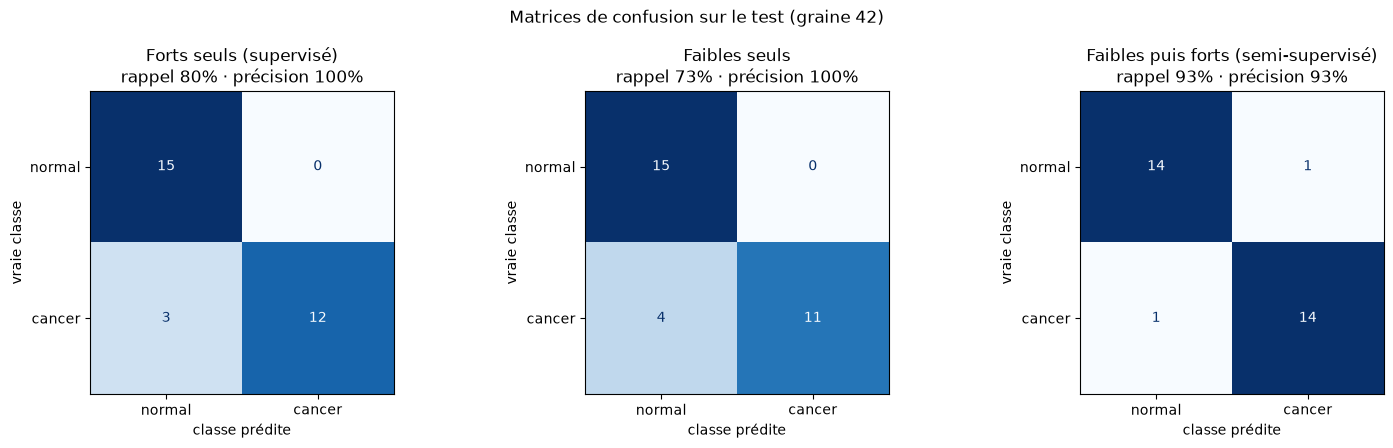

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, r in zip(axes, resultats):
    matrice = np.array(r["matrice [[VN, FP], [FN, VP]]"])
    ConfusionMatrixDisplay(matrice, display_labels=["normal", "cancer"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{r['approche']}\nrappel {r['rappel']:.0%} · précision {r['précision']:.0%}")
    ax.set_xlabel("classe prédite")
    ax.set_ylabel("vraie classe")
fig.suptitle("Matrices de confusion sur le test (graine 42)")
plt.tight_layout()
plt.show()


Avec la graine 42 : « forts seuls » rate 3 cancers sur 15, sans fausse alerte ; « faibles seuls » en rate 4, sans fausse alerte ; « faibles puis forts » n'en rate qu'un, au prix d'une fausse alerte. Les erreurs à surveiller en priorité sont celles de la case en bas à gauche (cancers ratés).

## 5. Robustesse : 10 graines

Les résultats dépendent du hasard (poids de départ de la tête, ordre des lots). On répète les trois approches avec 10 graines différentes, sans rien changer d'autre au protocole. Ce n'est pas une fuite de données : on ne choisit aucun réglage, on mesure seulement la stabilité des résultats.

rappel        précision            F2       
                     mean    std      mean    std   mean    std
approche                                                       
Faibles puis forts  0.880  0.028     0.937  0.022  0.891  0.023
Faibles seuls       0.747  0.028     1.000  0.000  0.786  0.025
Forts seuls         0.867  0.000     0.986  0.030  0.888  0.005

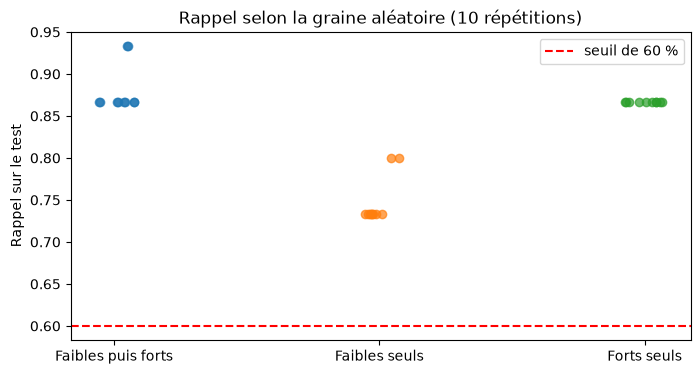

In [6]:
import matplotlib.pyplot as plt

repetitions = []
for graine in range(10):
    tete_forts = creer_tete(graine)
    entrainer(tete_forts, X_fort, y_fort, epoques=50, lr=1e-3, graine=graine)
    repetitions.append({**evaluer(tete_forts, "Forts seuls"), "graine": graine})

    tete_semi = creer_tete(graine)
    entrainer(tete_semi, X_faible, y_faible, epoques=10, lr=1e-3, graine=graine)
    repetitions.append({**evaluer(tete_semi, "Faibles seuls"), "graine": graine})
    entrainer(tete_semi, X_fort, y_fort, epoques=50, lr=1e-4, graine=graine)
    repetitions.append({**evaluer(tete_semi, "Faibles puis forts"), "graine": graine})

rep = pd.DataFrame(repetitions)
resume = rep.groupby("approche")[["rappel", "précision", "F2"]].agg(["mean", "std"]).round(3)
display(resume)

# Visualisation : le rappel obtenu avec chaque graine, par approche
fig, ax = plt.subplots(figsize=(8, 4))
for k, (nom, groupe) in enumerate(rep.groupby("approche")):
    ax.scatter(np.full(len(groupe), k) + np.random.uniform(-0.08, 0.08, len(groupe)), groupe["rappel"], alpha=0.7)
ax.set_xticks(range(rep["approche"].nunique()), sorted(rep["approche"].unique()))
ax.axhline(0.60, color="red", linestyle="--", label="seuil de 60 %")
ax.set_ylabel("Rappel sur le test")
ax.set_title("Rappel selon la graine aléatoire (10 répétitions)")
ax.legend()
plt.show()


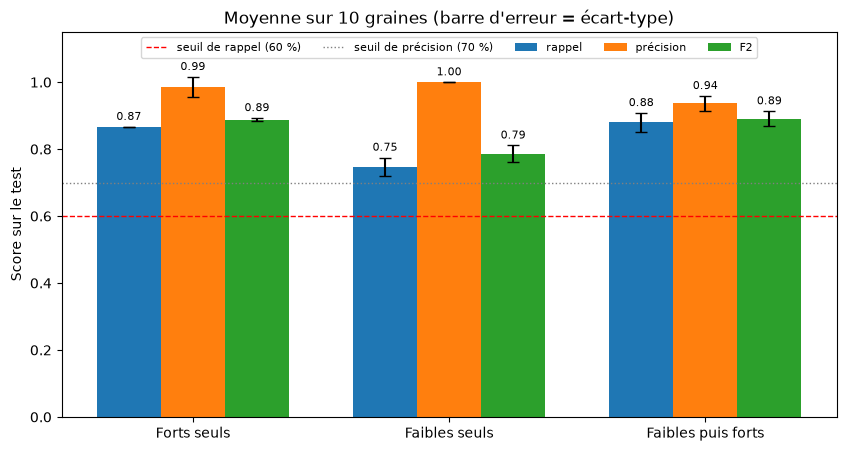

In [7]:
ordre = ["Forts seuls", "Faibles seuls", "Faibles puis forts"]
metriques = ["rappel", "précision", "F2"]
moyennes = rep.groupby("approche")[metriques].mean().loc[ordre]
ecarts = rep.groupby("approche")[metriques].std().loc[ordre]

x = np.arange(len(ordre))           # une position par approche : 0, 1, 2
largeur = 0.25                      # largeur de chaque barre
fig, ax = plt.subplots(figsize=(10, 5))
for k, m in enumerate(metriques):
    barres = ax.bar(x + (k - 1) * largeur, moyennes[m], largeur, yerr=ecarts[m], capsize=4, label=m)
    ax.bar_label(barres, fmt="%.2f", padding=3, fontsize=8)
ax.axhline(0.60, color="red", linestyle="--", linewidth=1, label="seuil de rappel (60 %)")
ax.axhline(0.70, color="gray", linestyle=":", linewidth=1, label="seuil de précision (70 %)")
ax.set_xticks(x, ordre)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Score sur le test")
ax.set_title("Moyenne sur 10 graines (barre d'erreur = écart-type)")
ax.legend(loc="upper center", ncol=5, fontsize=8)
plt.show()

Sur 10 graines, « forts seuls » et « faibles puis forts » sont équivalents (rappel 0,87 et 0,88, F2 0,89) et satisfont la definition of done (rappel > 60 %, précision > 70 %). « Faibles seuls » est nettement en retrait (rappel 0,75). « Forts seuls » est le plus stable : même rappel pour toutes les graines (13 cancers sur 15). Les barres d'erreur ne mesurent que la variabilité due au hasard de l'entraînement : l'incertitude liée à la petite taille du test (30 images) est plus grande.

## Conclusion de l'étape 4 (baseline)

**Protocole**, fixé avant de regarder le test : une tête de classification `Linear(2048, 2)` entraînée sur les embeddings ResNet-50 (backbone gelé), avec Adam et une légère régularisation.
- **Forts seuls** : 69 images, 50 epochs, lr = 0,001.
- **Faibles seuls** : 1 311 images (labels issus du clustering), 10 epochs, lr = 0,001.
- **Faibles puis forts** : le modèle précédent, puis 50 epochs sur les 69 images fortes, lr = 0,0001.

Toutes les approches sont évaluées sur le même test de 30 images (15 cancers), jamais utilisé auparavant.

| Approche (moyenne sur 10 graines) | Rappel | Précision | F2 |
|---|---|---|---|
| Forts seuls | 0,867 | 0,986 | 0,888 |
| Faibles seuls | 0,747 | 1,00 | 0,786 |
| Faibles puis forts | 0,880 | 0,937 | 0,891 |

**Lecture**
- Les trois approches dépassent largement l'objectif de 60 % de rappel.
- Les labels faibles seuls font moins bien que 69 labels fiables.
- Avec la graine 42, « faibles puis forts » semblait meilleur (1 cancer raté contre 3), mais sur 10 graines, les deux approches sont équivalentes : l'écart initial était dû au hasard.
- Interprétation : grâce aux embeddings ResNet, le problème est déjà bien résolu avec 69 images ; les labels faibles (justes à environ 83 % sur le train) ajoutent du volume, mais aussi des erreurs.

**Definition of done** : ✅ atteinte. Rappel moyen de 0,87 à 0,88 et précision de 0,94 à 0,99 pour les deux meilleures approches ; comparaison répétée sur 10 graines ; test isolé depuis l'étape 1.

**Limites** : test de 30 images (un cancer = 6,7 points de rappel) ; taux d'apprentissage différent en phase 2 (convention du fine-tuning) ; biais du plan de coupe non corrigé.

**Pistes** : labels faibles filtrés par un seuil de confiance ; LabelSpreading ; évaluation sur les seules coupes axiales ; fine-tuning de `layer4` ; validation croisée.
